True


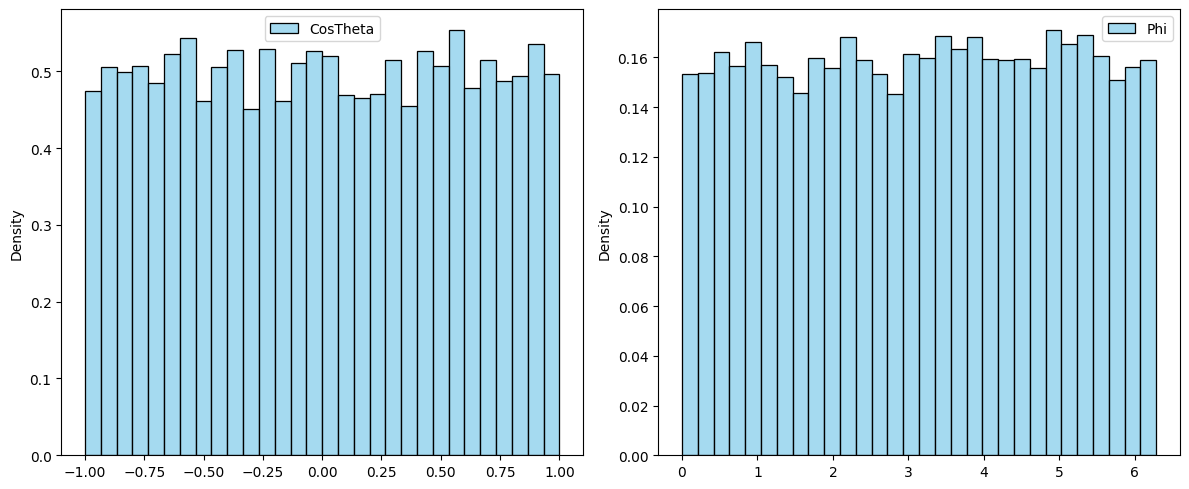

min_dist = 1.0000394557767098, delta = 3.945577670982914e-05
max_dist = 2.999808984580791, delta = 0.00019101541920907295


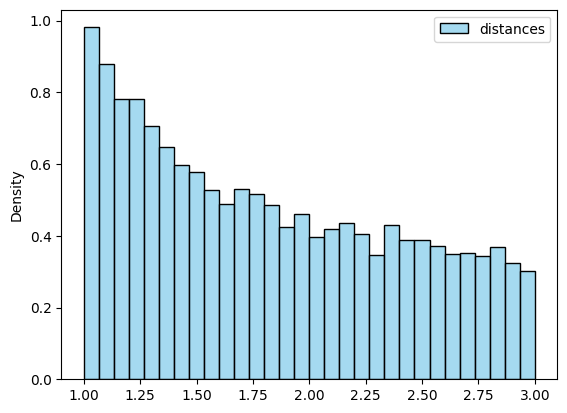

In [31]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class Source():
    def __init__(self, E:float,origin:np.ndarray,Y=1e4):
        self.Y=Y
        self.N=int(E*Y)
        self.origin=origin
        self.PhotonArray=self.random_distribution()
    def random_distribution(self):
        phi=np.random.uniform(0,2*np.pi, self.N)
        cosTheta=np.random.uniform(-1,1,self.N)
        sinTheta=np.sqrt(1-cosTheta*cosTheta)
        return np.array([sinTheta*np.cos(phi),sinTheta*np.sin(phi), cosTheta])
        #добавлен метод для учитывания сдвига точки источника для задания 4 
    def distance_traversed(self,R:float):
        t=-self.origin@self.PhotonArray+np.sqrt(R**2-np.sum(self.origin**2)+(self.origin@self.PhotonArray)*(self.origin@self.PhotonArray))
        return t
        


origin=np.array([0,0,1])
# print(origin.shape)
S1=Source(1,origin)

#тесты на работоспособность класса

#единичаня длина 
def test_IsUnit():
    print(np.all(np.sqrt(np.sum(S1.PhotonArray**2, axis=0)))==1.) 

#равномерность распределения (визуальный тест распределения)  
def test_IsUniform():
    # np.sum(PhotonArray,axis=1)/S1.N #стремится к нулю при N->inf
    x, y, z = S1.PhotonArray
    CosTheta = z
    Phi = np.arctan2(y, x)   
    Phi = (Phi + 2*np.pi) % (2*np.pi)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))    
    sns.histplot(CosTheta, bins=30, stat='density', kde=False, color='skyblue', edgecolor='black',label='CosTheta',ax=axes[0])
    sns.histplot(Phi, bins=30, stat='density', kde=False, color='skyblue', edgecolor='black',label='Phi',ax=axes[1])
    axes[0].legend()
    axes[1].legend()
    plt.tight_layout()
    plt.show()

#пройденное растояние до поглощения 
def test_TraversedDistance():
    print(f'min_dist = {np.min(S1.distance_traversed(2))}, delta = {np.abs(np.min(S1.distance_traversed(2))-(2-np.sqrt(np.sum(origin**2))))}') #минимальное расстояние должно быть примерно 2-|origin|
    print(f'max_dist = {np.max(S1.distance_traversed(2))}, delta = {np.abs(np.max(S1.distance_traversed(2))-(2+np.sqrt(np.sum(origin**2))))}')#максимальное расстояние должно быть примерно 2+|origin|
    sns.histplot(S1.distance_traversed(2), bins=30, stat='density', kde=False, color='skyblue', edgecolor='black',label='distances')
    plt.legend()
    plt.show()

test_IsUnit()
test_IsUniform()
test_TraversedDistance()